# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [64]:
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")

print("Forme :", brut.shape)

print("\nTypes des colonnes :")
print(brut.dtypes)

print("\nValeurs manquantes par colonne :")
print(brut.isna().sum())

print("\nNombre de doublons :", brut.duplicated().sum())

Forme : (300, 4)

Types des colonnes :
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes par colonne :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Nombre de doublons : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [46]:
nb_ecritures = brut["quartier"].nunique()
print(f"{nb_ecritures} écritures.")

43 écritures.


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [47]:
conversion_forcee = pd.to_numeric(brut["kwh"], errors="coerce")
non_numeriques = brut["kwh"][conversion_forcee.isna() & brut["kwh"].notna()]
print("Valeurs non numériques que pd.to_numeric ne sait pas convertir :")
print(non_numeriques.unique()[:10])

Valeurs non numériques que pd.to_numeric ne sait pas convertir :
<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh']
Length: 10, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [63]:
propre = brut.copy()

propre["kwh"] = (
    propre["kwh"]
    .astype(str)
    .str.replace("kWh", "", case=False)
    .str.replace(r"\s+", "", regex=True)
)

propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")

print("Manquants restants dans kwh :", propre["kwh"].isna().sum())

Manquants restants dans kwh : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [62]:
quartiers_ref = pd.read_csv("donnees/quartiers.csv")
noms_officiels = quartiers_ref["quartier"].tolist()

mapping = {q.strip().lower(): q for q in noms_officiels}

propre["quartier"] = propre["quartier"].str.strip().str.lower().map(mapping)

print("Nombre de quartiers uniques :", propre["quartier"].nunique())
print("Nombre de valeurs non reconnues:", propre["quartier"].isna().sum())

Nombre de quartiers uniques : 12
Nombre de valeurs non reconnues: 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [50]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])
propre.shape

(279, 4)

**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [51]:
mediane_par_quartier = propre.groupby("quartier")["kwh"].transform("median")

masque_anomalies = propre["kwh"] > 3 * mediane_par_quartier
anomalies = propre[masque_anomalies]

print("Relevés anormaux détectés :")
print(anomalies[["mois", "quartier", "kwh"]])

propre.loc[masque_anomalies, "kwh"] = propre.loc[masque_anomalies, "kwh"] / 10

propre["kwh"] = propre["kwh"].astype("int64")

print("\nMaximum de kwh :", propre["kwh"].max())

Relevés anormaux détectés :
        mois        quartier        kwh
90   2025-02       Delmas 33  3602600.0
140  2025-02       Delmas 75  2012700.0
200  2024-02  Morne Calvaire  1439200.0
251  2024-01          Rue 15   997700.0

Maximum de kwh : 742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [52]:
reference = pd.read_csv("donnees/consommation.csv")
ref_aligne = reference.merge(propre[["mois", "quartier"]], on=["mois", "quartier"])[propre.columns]
propre.reset_index(drop=True).equals(ref_aligne)

True

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [53]:
print("Lignes avant jointure :", len(propre))

avec_quartiers = propre.merge(quartiers_ref, on="quartier", how="inner")
print("Lignes après jointure :", len(avec_quartiers))

avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

verif_bas = avec_quartiers[
    (avec_quartiers["quartier"] == "Bas-Peu-de-Chose") & 
    (avec_quartiers["mois"] == "2024-01")
]
print("\nVérification Bas-Peu-de-Chose 2024-01 :")
print(verif_bas[["mois", "quartier", "kwh_par_abonne"]])

Lignes avant jointure : 279
Lignes après jointure : 279

Vérification Bas-Peu-de-Chose 2024-01 :
      mois          quartier  kwh_par_abonne
0  2024-01  Bas-Peu-de-Chose            85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [54]:
meteo = pd.read_csv("donnees/meteo.csv")

print("Lignes avant jointure météo :", len(avec_quartiers))
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="inner")
print("Lignes après jointure météo :", len(avec_meteo))

print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())

Lignes avant jointure météo : 279
Lignes après jointure météo : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [55]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

relue = pd.read_csv("donnees/consommation_propre.csv")
print("Forme de consommation_propre.csv :", relue.shape)

Forme de consommation_propre.csv : (279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [56]:
moy_par_type = avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1)
print("Consommation moyenne par abonné par type :")
print(moy_par_type)

classement_quartiers = (
    avec_meteo.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .round(1)
    .sort_values(ascending=False)
)
print("\nClassement des 12 quartiers :")
print(classement_quartiers)

Consommation moyenne par abonné par type :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des 12 quartiers :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut : Les quartiers commerciaux consomment en moyenne plus de 3 fois plus par abonné (393.2 kWh) que les quartiers résidentiels (117.4 kWh). Les trois quartiers en tête du classement sont tous commerciaux : Centre-ville (468.7 kWh), Place Saint-Pierre (458.3 kWh) et Delmas 33 (374.4 kWh). À l'inverse, les quartiers résidentiels présentent des niveaux de consommation par abonné nettement plus faibles.**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Tableau croisé :
annee            2024   2025  hausse_pct
commune                                 
Cap-Haïtien      4.59   5.62        22.5
Delmas          11.61  11.74         1.1
Port-au-Prince  10.09  10.31         2.3
Pétion-Ville     8.60   9.68        12.6


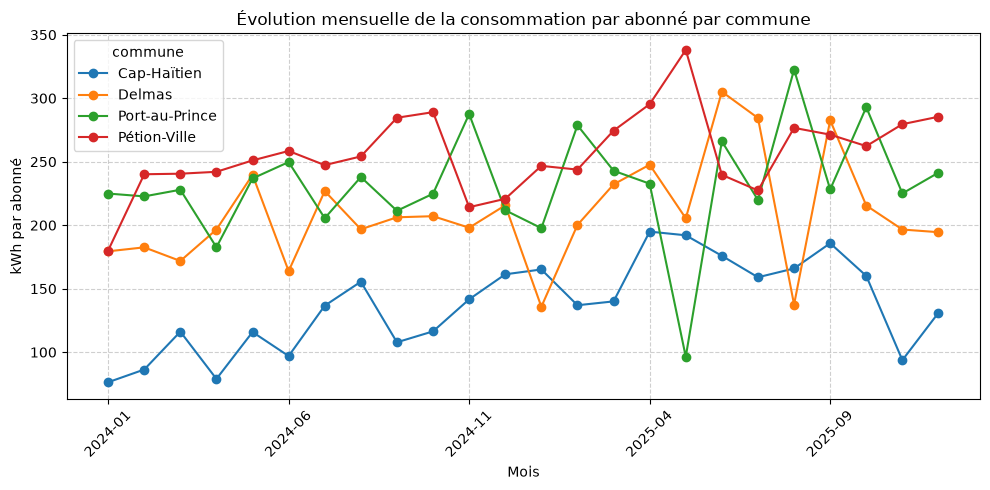

In [57]:
import matplotlib.pyplot as plt

pivot = avec_meteo.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")

pivot["hausse_pct"] = ((pivot[2025] - pivot[2024]) / pivot[2024] * 100).round(1)

pivot[2024] = (pivot[2024] / 1e6).round(2)
pivot[2025] = (pivot[2025] / 1e6).round(2)

print("Tableau croisé :")
print(pivot)

mensuel = avec_meteo.groupby(["mois", "commune"])["kwh_par_abonne"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
mensuel.plot(ax=ax, marker="o")
ax.set_title("Évolution mensuelle de la consommation par abonné par commune")
ax.set_ylabel("kWh par abonné")
ax.set_xlabel("Mois")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**Ce qu'on en conclut : Cap-Haïtien affiche la plus forte progression entre 2024 et 2025 avec une hausse de +22.4 % (de 4.59 à 5.62 millions de kWh). À l'opposé, Delmas présente une consommation quasiment stable avec seulement +1.1 % de hausse. Les 4 courbes révèlent des niveaux de consommation par abonné bien différenciés d'une commune à l'autre tout au long des 24 mois.**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

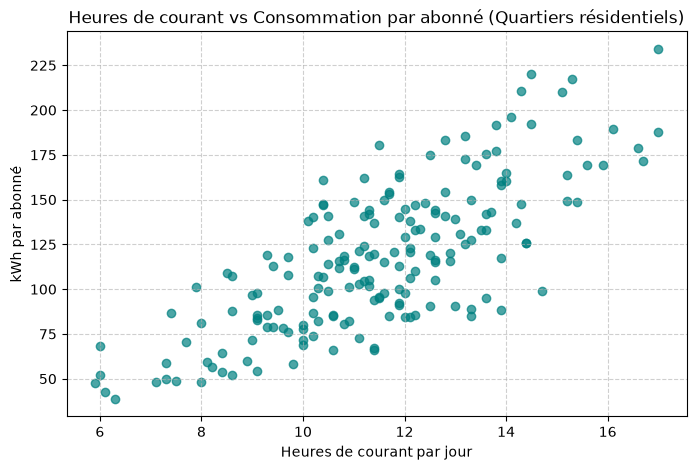

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [58]:
residentiel = avec_meteo[avec_meteo["type"] == "Résidentiel"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(residentiel["heures_courant"], residentiel["kwh_par_abonne"], alpha=0.7, color="teal")
ax.set_title("Heures de courant vs Consommation par abonné (Quartiers résidentiels)")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("kWh par abonné")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()

corr_courant = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"]).round(2)
corr_temp = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"]).round(2)

print(f"Corrélation avec les heures de courant : {corr_courant}")
print(f"Corrélation avec la température : {corr_temp}")

**Ce qu'on en conclut : Dans les quartiers résidentiels, la consommation est très fortement corrélée aux heures de courant disponibles (r = 0.76), tandis qu'elle est insensible à la température (r = -0.15). C'est la présence physique d'électricité sur le réseau qui pilote la consommation, et non la chaleur ambiante.**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Statistiques des heures de courant par commune :
                mediane    Q1    Q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


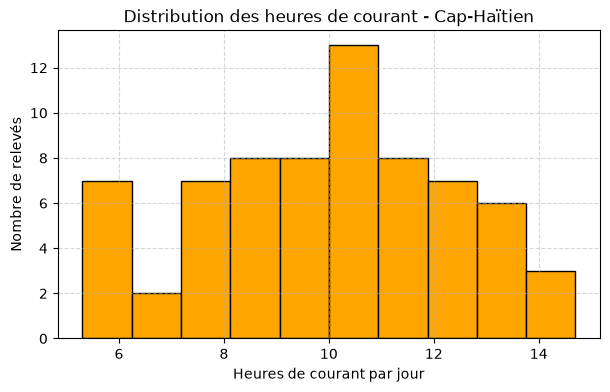


Relevés de 2025 avec moins de 8 heures de courant par jour :
        mois      commune   quartier  heures_courant
81   2025-01       Delmas  Delmas 33             7.4
227  2025-08  Cap-Haïtien   Carénage             7.3
253  2025-11  Cap-Haïtien     Rue 15             5.9


In [59]:
stats_coupures = avec_meteo.groupby("commune")["heures_courant"].agg(
    mediane="median",
    Q1=lambda s: s.quantile(0.25),
    Q3=lambda s: s.quantile(0.75)
).round(1)
print("Statistiques des heures de courant par commune :")
print(stats_coupures)

cap = avec_meteo[avec_meteo["commune"] == "Cap-Haïtien"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(cap["heures_courant"], bins=10, color="orange", edgecolor="black")
ax.set_title("Distribution des heures de courant - Cap-Haïtien")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("Nombre de relevés")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

critiques_2025 = avec_meteo[(avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8)]
print("\nRelevés de 2025 avec moins de 8 heures de courant par jour :")
print(critiques_2025[["mois", "commune", "quartier", "heures_courant"]])

**Ce qu'on en conclut : Cap-Haïtien subit les coupures les plus sévères, avec une médiane de seulement 10.0 heures de courant par jour, contre 11.6 à 11.9 heures dans les autres communes. Durant l'année 2025, 3 relevés sont tombés en dessous du seuil critique de 8 heures par jour, localisés à Carénage, Delmas 33 et Rue 15.**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [60]:
top3 = avec_meteo.sort_values(by="kwh", ascending=False).head(3)
print("Les 3 plus grosses consommations :")
print(top3[["mois", "quartier", "type", "kwh"]])

Les 3 plus grosses consommations :
       mois      quartier        type     kwh
87  2025-07     Delmas 33  Commercial  742780
56  2024-11  Centre-ville  Commercial  597730
88  2025-09     Delmas 33  Commercial  591420


**Ce qu'on en conclut : Les trois consommations les plus massives de la période appartiennent toutes au secteur commercial : Delmas 33 en juillet 2025 (742 780 kWh), Centre-ville en novembre 2024 (597 730 kWh) et Delmas 33 en septembre 2025 (591 420 kWh). Ces pics correspondent à des zones à forte densité d'activités marchandes.**

## 9. Conclusion

La consommation d'électricité dans les quartiers résidentiels suit directement la disponibilité du service (corrélation de 0.76 avec les heures de courant) et non la météo, la température présentant une corrélation légèrement négative et négligeable (-0.15). Les ménages consomment dès que le courant est distribué, quelle que soit la chaleur extérieure. Cependant, une forte corrélation ne prouve pas une causalité exclusive : elle traduit ici une demande contrainte par le rationnement de l'offre plutôt qu'une absence totale de besoins liés au climat.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.